In [1]:
from requirements import *
from utils.tl.score_genes import score_genes

# Extended Data Figure 12

In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)

## ED Figure 12i. Responder vs Non-responder T cell cytotoxicity score calculation

In [3]:
responders = ["MDS-6", "MDS-30", "MDS-32", "MDS-33", "MDS-34", "MDS-36", "MDS-37", "MDS-40"]
nonresp = ["MDS-16", "MDS-2", "MDS-25", "MDS-27", "MDS-29", "MDS-38", "MDS-41"]
adata_xenv1.obs['response'] = 'NA'
adata_xenv1.obs.loc[adata_xenv1.obs['study_id'].isin(responders), 'response'] = 'Responder'
adata_xenv1.obs.loc[adata_xenv1.obs['study_id'].isin(nonresp), 'response'] = 'Non-Responder'

In [4]:
ad_tcell = adata_xenv1[adata_xenv1.obs['ct_general'].isin(['T Cell'])]
ad_tcell = ad_tcell[ad_tcell.obs['response'] != 'NA'].copy()
score_genes({'cyto' : ['GNLY','GZMB','KLRG1','NKG7','PRF1','TBX21']}, ad_tcell)
###### ISG signature 
sig_df = None
for samp in ad_tcell.obs['study_id'].unique():
    print(samp)
    currsamp = ad_tcell[ad_tcell.obs['study_id'] == samp].copy()
    if (sum(currsamp.obs['response'].value_counts() < 10) > 0):
        print('skipped')
        continue
    else:        
        print(pd.crosstab(index=currsamp.obs["ct_refined"], columns=currsamp.obs["response"]))
        print(currsamp.obs.groupby(['response'])['zscore_cyto'].agg(['mean']))
        currdf = currsamp.obs.groupby(['response'])['zscore_cyto'].agg(['mean'])
        currdf['sample'] = samp
        sig_df = pd.concat([sig_df, currdf])

sig_df['cat'] = sig_df.index


MDS-2
response                  Non-Responder
ct_refined                             
CD4 Memory                          314
CD4 Naive/Central Memory           1411
CD4 Treg                            188
CD8 Memory                         1703
CD8 Naive                            88
                   mean
response               
Non-Responder -0.001741
MDS-6
response                  Responder
ct_refined                         
CD4 Memory                      174
CD4 Naive/Central Memory        587
CD4 Treg                         62
CD8 Memory                      822
CD8 Naive                        33
               mean
response           
Responder  0.227762
MDS-25
response                  Non-Responder
ct_refined                             
CD4 Memory                           39
CD4 Naive/Central Memory            499
CD4 Treg                             10
CD8 Memory                          313
CD8 Naive                            23
                   mean
response     

<Axes: xlabel='cat', ylabel='mean'>

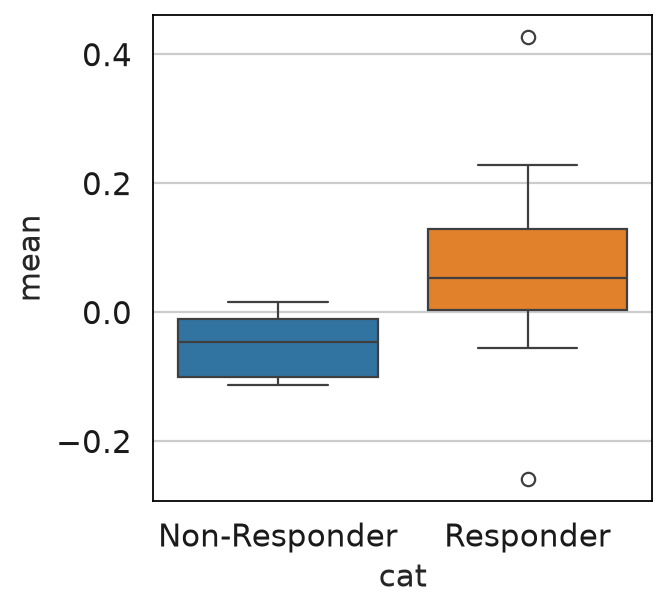

In [6]:
sc.set_figure_params(figsize=(4, 4))
sns.boxplot(data=sig_df, x='cat', y='mean', hue='cat')